# Probabilistic Email Threat Detection Using Maximum Entropy

This project follows the required engineering workflow:

**Problem → Data → Preprocessing → Representation → Model → Experiment → Results → Interpretation → Limitations**

The objective is not only to train a model, but to understand its probabilities, errors, important features, and practical limitations.

## 1. Problem Definition

Email systems process huge numbers of legitimate and malicious messages. A security-oriented NLP system should distinguish normal communication from phishing and spam.

This is a **supervised probabilistic classification** problem because the training examples have known labels. The MaxEnt model estimates a conditional distribution of the form `P(class | email_features)`.

### Classes

- **0 — Ham:** legitimate message
- **1 — Phish:** phishing message
- **2 — Spam:** unsolicited/unwanted message

### Main question

> Can a Maximum Entropy classifier using TF-IDF text features reliably distinguish Ham, Phish, and Spam messages?

## 2. Dataset

This project uses a large-scale unified and deduplicated collection of text messages/emails containing three classes: Ham, Phish, and Spam.

Source: https://www.kaggle.com/datasets/akshatsharma2/the-biggest-spam-ham-phish-email-dataset-300000

## 3. Libraries and Reproducibility

In [ ]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment ready")

Environment ready


## 4. Load the Dataset

In [33]:
DATA_PATH = Path("archive/df.csv")

if not DATA_PATH.exists():
    print("Dataset not found. Update DATA_PATH before running the notebook.")
else:
    print("Dataset:", DATA_PATH.resolve())

Dataset: C:\Development\email_spam_detection\archive\df.csv


In [34]:
def load_dataset(path):
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix in [".xlsx", ".xls"]:
        return pd.read_excel(path)
    if suffix == ".json":
        return pd.read_json(path)
    if suffix in [".jsonl", ".ndjson"]:
        return pd.read_json(path, lines=True)
    raise ValueError(f"Unsupported format: {suffix}")

if DATA_PATH.exists():
    df = load_dataset(DATA_PATH)
    print("Shape:", df.shape)
else:
    df = pd.DataFrame()
    print("No dataset loaded.")

Shape: (365448, 2)


In [35]:
if not df.empty:
    print("Columns:", df.columns.tolist())
    print("Dataset Sample:")
    display(df.head())
    print("Data Types:")
    display(df.dtypes)
    print("Missing Values:")
    display(df.isna().sum().sort_values(ascending=False).head(20))

Columns: ['label', 'text']
Dataset Sample:


,label,text
0,0,wrong bill grace i ' ll forward original messa...
1,0,i have continued the hilcorp old ocean deal da...
2,0,several related issues have resulted in an inc...
3,0,one year rate for this one will be escapenumbe...
4,0,attached is the weekly deal report for escapen...


Data Types:


label    int64
text       str
dtype: object

Missing Values:


text     2
label    0
dtype: int64

In [36]:
df["text"].sample(1).values[0] if not df.empty else print("No data to sample.")

'enron total trading daily loss\nlimit - ( $ 125 . 00 million )\nloss - ( $ 193 . 51 million )\n* note : the dpr is currently preliminary and subject to change which may cause an adjustment to the total loss .'

In [37]:
df.dropna(subset=["text", "label"], inplace=True)

In [38]:
df.shape

(365446, 2)

## 5. Label Standardization and Cleaning

We standardize labels to readable class names. Missing messages, empty messages, unknown labels, and exact duplicate texts are removed.

We avoid aggressive text cleaning because URLs, punctuation, digits, and domains can be useful phishing indicators.

In [39]:
LABEL_MAP = {
    0: "Ham", 1: "Phish", 2: "Spam",
    "0": "Ham", "1": "Phish", "2": "Spam",
    "ham": "Ham", "phish": "Phish", "phishing": "Phish", "spam": "Spam"
}

data = df.copy()

data["label"] = data["label"].apply(lambda x: LABEL_MAP.get(x, LABEL_MAP.get(str(x).strip().lower(), np.nan)))
data["text"] = data["text"].astype("string")
data["text"] = data["text"].str.strip()
data = data[data["text"].str.len() > 0]

data = data[data["label"].isin(["Ham", "Phish", "Spam"])]
before = len(data)
duplicate_count = data["text"].duplicated().sum()
data = data.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Rows after cleaning:", len(data))
print("Exact duplicates removed:", duplicate_count)
print("Rows retained:", len(data), "of", before)

Rows after cleaning: 279510
Exact duplicates removed: 85935
Rows retained: 279510 of 365445


In [40]:
if not data.empty:
    print("Class counts:")
    display(data["label"].value_counts())
    print("Class proportions:")
    display(data["label"].value_counts(normalize=True).round(4))

Class counts:


label
Ham      128076
Spam     108594
Phish     42840
Name: count, dtype: int64

Class proportions:


label
Ham      0.4582
Spam     0.3885
Phish    0.1533
Name: proportion, dtype: float64

## 6. Exploratory Data Analysis — Class Distribution

Class balance matters because a model can obtain deceptively high accuracy by predicting the majority class. This is why a majority baseline and macro-F1 are included later.

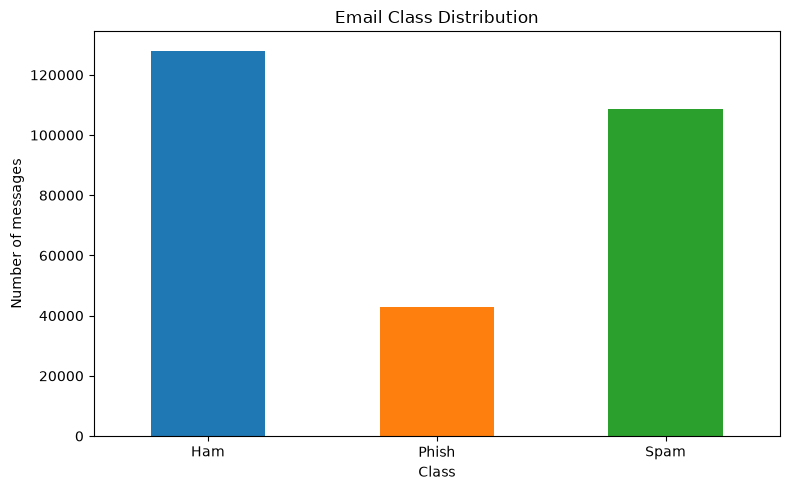

In [41]:
if not data.empty:
    counts = data["label"].value_counts().reindex(["Ham", "Phish", "Spam"])
    ax = counts.plot(kind="bar", figsize=(8, 5), color=["#1f77b4", "#ff7f0e", "#2ca02c"])
    ax.set_title("Email Class Distribution")
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of messages")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 7. Text Length Analysis

We inspect character and word counts to understand the data. These variables are mainly exploratory; the main classifier uses TF-IDF text features.

In [42]:
if not data.empty:
    data["char_count"] = data["text"].str.len()
    data["word_count"] = data["text"].str.split().str.len()
    display(data.groupby("label")[["char_count", "word_count"]].agg(["mean", "median", "std"]).round(2))

char_count                  word_count                
            mean median       std       mean median      std
label                                                       
Ham      2212.95  941.0  35257.67     342.25  150.0  4903.33
Phish    1060.79  391.0  21205.27     121.36   55.0   594.79
Spam      1414.8  678.0   2370.21     211.83  107.0   334.55

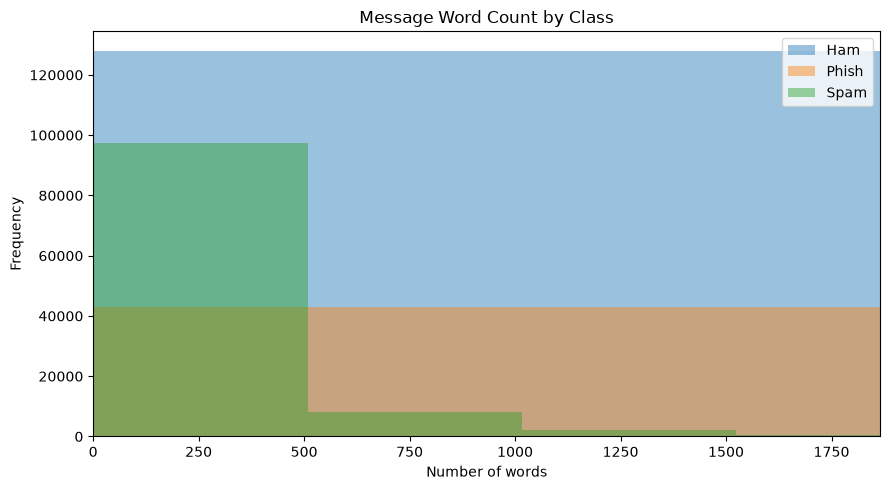

In [43]:
if not data.empty:
    plt.figure(figsize=(9, 5))
    for label in ["Ham", "Phish", "Spam"]:
        values = data.loc[data["label"] == label, "word_count"]
        plt.hist(values, bins=50, alpha=0.45, label=label)
    plt.title("Message Word Count by Class")
    plt.xlabel("Number of words")
    plt.ylabel("Frequency")
    plt.xlim(0, data["word_count"].quantile(0.99))
    plt.legend()
    plt.tight_layout()
    plt.show()

## 8. Security-Oriented Exploratory Features

We inspect simple indicators often associated with email security: URLs, email addresses, digits, exclamation marks, and uppercase characters.

In [44]:
def security_features(text):
    text = str(text)
    return pd.Series({
        "url_count": len(re.findall(r"https?://\S+|www\.\S+", text, flags=re.I)),
        "email_count": len(re.findall(r"[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}", text)),
        "digit_count": sum(ch.isdigit() for ch in text),
        "exclamation_count": text.count("!"),
        "uppercase_count": sum(ch.isupper() for ch in text),
    })

if not data.empty:
    sec = data["text"].apply(security_features)
    data = pd.concat([data, sec], axis=1)
    display(data.groupby("label")[["url_count", "email_count", "digit_count", "exclamation_count", "uppercase_count"]].mean().round(2))

,url_count,email_count,digit_count,exclamation_count,uppercase_count
label,,,,,
Ham,0.0,0.0,9.34,0.08,0.0
Phish,0.0,0.0,68.40,0.00,0.0
Spam,0.0,0.0,4.99,0.22,0.0


In [45]:
data.sample(5)

,label,text,char_count,word_count,url_count,email_count,digit_count,exclamation_count,uppercase_count
205953,Spam,ci ialis softabs is better than pfizer viiagrr...,421,69,0,0,0,0,0
1930,Ham,daren fyi orig was escapenumber escapenumber r...,1084,149,0,0,0,0,0
66653,Ham,martin morgan wrote oops taking a look at the ...,4498,683,0,0,0,0,0
154631,Phish,arley arvandus manleysetoncocom dear 4c090049a...,278,41,0,0,53,0,0
15358,Spam,we have the hottest pornostars pics and videos...,335,51,0,0,0,0,0


## 9. Text Preprocessing

We normalize whitespace and lowercase the text. We intentionally keep most punctuation, numbers, and URLs because removing them completely could destroy security-related signals.

The preprocessing is deliberately conservative: the classifier should learn useful patterns from the original message rather than from an overly cleaned representation.

In [46]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()

data["clean_text"] = data["text"].apply(clean_text)
display(data[["text", "clean_text", "label"]].head())

,text,clean_text,label
0,wrong bill grace i ' ll forward original messa...,wrong bill grace i ' ll forward original messa...,Ham
1,i have continued the hilcorp old ocean deal da...,i have continued the hilcorp old ocean deal da...,Ham
2,several related issues have resulted in an inc...,several related issues have resulted in an inc...,Ham
3,one year rate for this one will be escapenumbe...,one year rate for this one will be escapenumbe...,Ham
4,attached is the weekly deal report for escapen...,attached is the weekly deal report for escapen...,Ham


## 10. Exporting the cleaned dataset


In [50]:
data.to_csv("archive/cleaned_email_data.csv", index=False)